In [ ]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# ============================================
# 2. LOAD DATASET
# ============================================

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('diabetes.csv')

print("Dataset loaded successfully!")

Saving diabetes.csv to diabetes (1).csv
Dataset loaded successfully!


In [ ]:
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1
5,5,116,74.0,27,102.5,25.6,0.201,30,0
6,3,78,50.0,32,88.0,31.0,0.248,26,1
7,10,115,70.0,27,102.5,35.3,0.134,29,0
8,2,197,70.0,45,543.0,30.5,0.158,53,1
9,8,125,96.0,32,169.5,34.3,0.232,54,1


In [ ]:
# ============================================
# 1.3 DATASET SHAPE
# ============================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 768
Number of columns: 9


In [ ]:
# ============================================
# 1.4 COLUMN NAMES
# ============================================

print("Columns:")
print(df.columns.tolist())

Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [ ]:
# ============================================
# 1.5 DATA TYPES
# ============================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


In [ ]:
# ============================================
# 1.6 MISSING VALUES
# ============================================

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
# ============================================
# CHECK ZERO VALUES
# ============================================

zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("Number of zero values:")
print((df[zero_columns] == 0).sum())

Number of zero values:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
# ============================================
# 1.8 TARGET DISTRIBUTION
# ============================================

print(df['Outcome'].value_counts())

print("\nPercentage distribution:")
print(df['Outcome'].value_counts(normalize=True) * 100)

Outcome
0    500
1    268
Name: count, dtype: int64

Percentage distribution:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


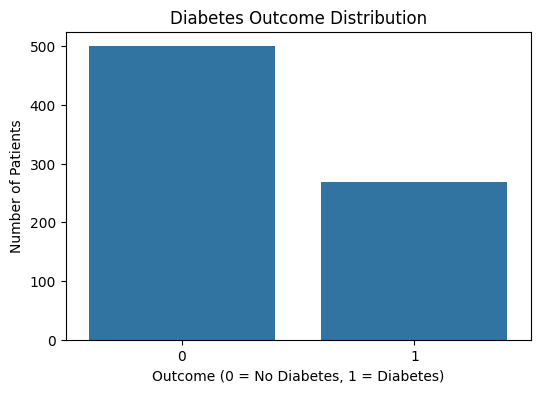

In [ ]:
# Plot target distribution

plt.figure(figsize=(6, 4))

sns.countplot(x='Outcome', data=df)

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Number of Patients')

plt.show()

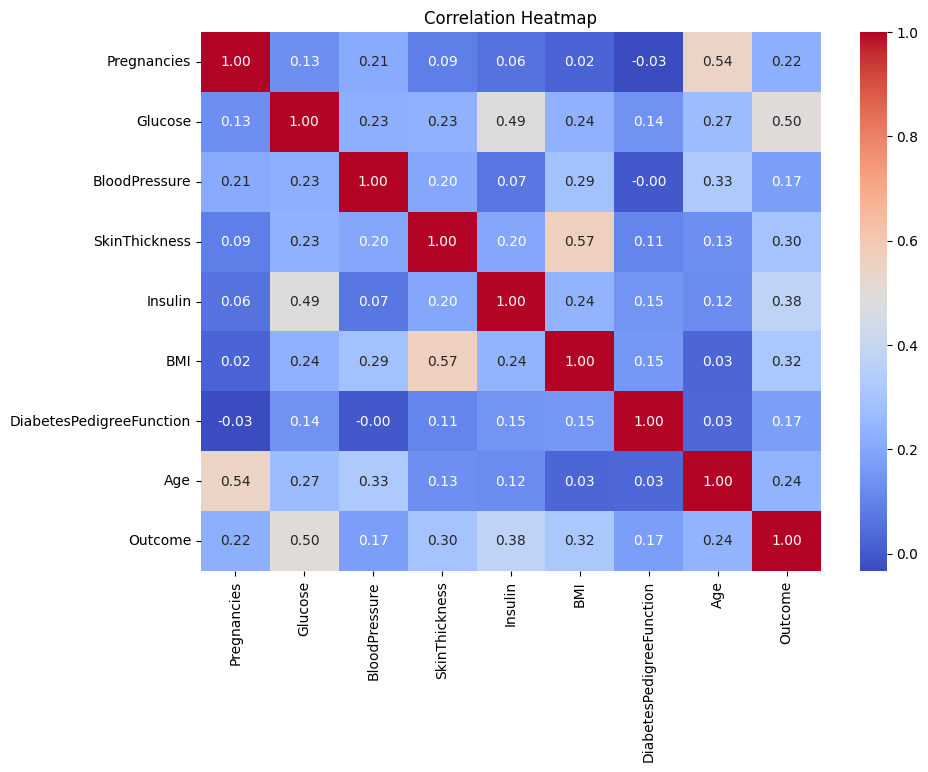

In [ ]:
# ============================================
# 1.9 CORRELATION HEATMAP
# ============================================

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
# ============================================
# 2.1 SEPARATE FEATURES AND TARGET
# ============================================

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (768, 8)
Target shape: (768,)


In [ ]:
# ============================================
# 2.2 TRAIN-TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [ ]:
# ============================================
# 2.3 FEATURE SCALING
# ============================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [ ]:
# ============================================
# 3.1 LOGISTIC REGRESSION
# ============================================

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
# Predictions
y_pred_lr = logistic_model.predict(X_test_scaled)

# Probability predictions
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated!")

Predictions generated!


In [ ]:
# ============================================
# 3.3 RANDOM FOREST
# ============================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
# Predictions
y_pred_rf = rf_model.predict(X_test)

# Probability predictions
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated!")

Predictions generated!


In [ ]:
# ============================================
# 4.1 LOGISTIC REGRESSION EVALUATION
# ============================================

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("=" * 40)

print(f"Accuracy :  {lr_accuracy:.4f}")
print(f"Precision:  {lr_precision:.4f}")
print(f"Recall   :  {lr_recall:.4f}")
print(f"F1 Score :  {lr_f1:.4f}")
print(f"ROC-AUC  :  {lr_roc_auc:.4f}")

Logistic Regression Results
Accuracy :  0.7078
Precision:  0.5882
Recall   :  0.5556
F1 Score :  0.5714
ROC-AUC  :  0.8263


In [ ]:
# ============================================
# 4.2 RANDOM FOREST EVALUATION
# ============================================

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("=" * 40)

print(f"Accuracy :  {rf_accuracy:.4f}")
print(f"Precision:  {rf_precision:.4f}")
print(f"Recall   :  {rf_recall:.4f}")
print(f"F1 Score :  {rf_f1:.4f}")
print(f"ROC-AUC  :  {rf_roc_auc:.4f}")

Random Forest Results
Accuracy :  0.8701
Precision:  0.8269
Recall   :  0.7963
F1 Score :  0.8113
ROC-AUC  :  0.9458


In [ ]:
print("Logistic Regression Classification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=['No Diabetes', 'Diabetes']
    )
)

Logistic Regression Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.77      0.79      0.78       100
    Diabetes       0.59      0.56      0.57        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.70      0.71      0.71       154



In [ ]:
print("Random Forest Classification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=['No Diabetes', 'Diabetes']
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.89      0.91      0.90       100
    Diabetes       0.83      0.80      0.81        54

    accuracy                           0.87       154
   macro avg       0.86      0.85      0.86       154
weighted avg       0.87      0.87      0.87       154



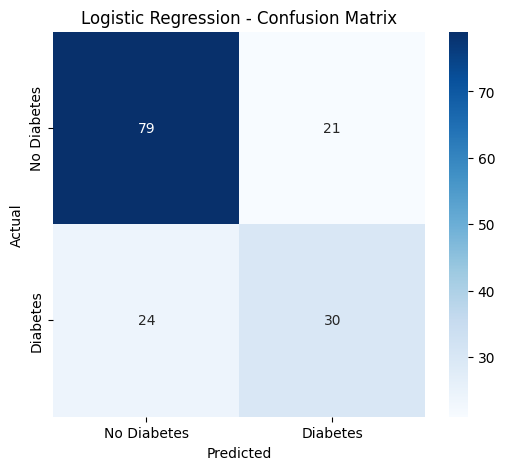

In [ ]:
# ============================================
# LOGISTIC REGRESSION CONFUSION MATRIX
# ============================================

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

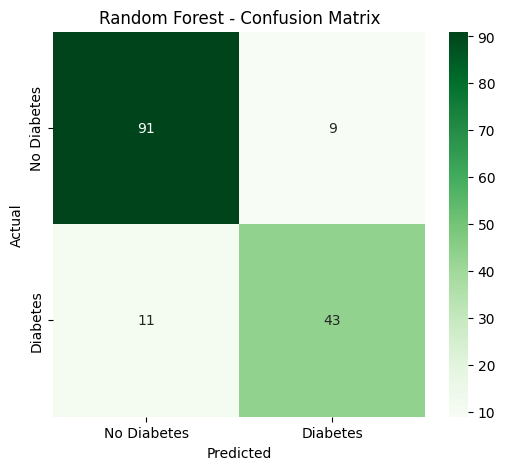

In [ ]:
# ============================================
# RANDOM FOREST CONFUSION MATRIX
# ============================================

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

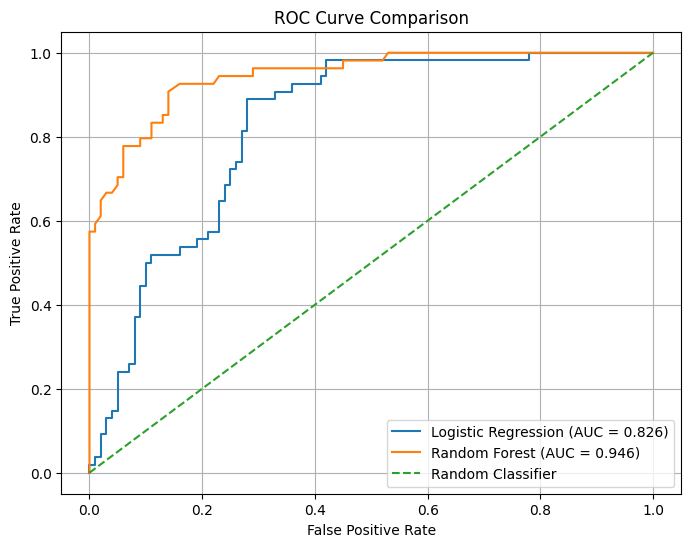

In [ ]:
# ============================================
# 5. ROC CURVE
# ============================================

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f'Logistic Regression (AUC = {lr_roc_auc:.3f})'
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {rf_roc_auc:.3f})'
)

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve Comparison')

plt.legend()
plt.grid()

plt.show()

**Logistic regression has good AUC curve bu Random forest roc curve is best as it has excellent performance.**

In [ ]:
# ============================================
# 6. MODEL COMPARISON
# ============================================

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest'
    ],

    'Accuracy': [
        lr_accuracy,
        rf_accuracy
    ],

    'Precision': [
        lr_precision,
        rf_precision
    ],

    'Recall': [
        lr_recall,
        rf_recall
    ],

    'F1 Score': [
        lr_f1,
        rf_f1
    ],

    'ROC-AUC': [
        lr_roc_auc,
        rf_roc_auc
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.707792,0.588235,0.555556,0.571429,0.826296
1,Random Forest,0.870130,0.826923,0.796296,0.811321,0.945833


In [ ]:
# Round values for better presentation

results_rounded = results.copy()

metric_columns = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC-AUC'
]

results_rounded[metric_columns] = results_rounded[metric_columns].round(4)

results_rounded

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7078,0.5882,0.5556,0.5714,0.8263
1,Random Forest,0.8701,0.8269,0.7963,0.8113,0.9458


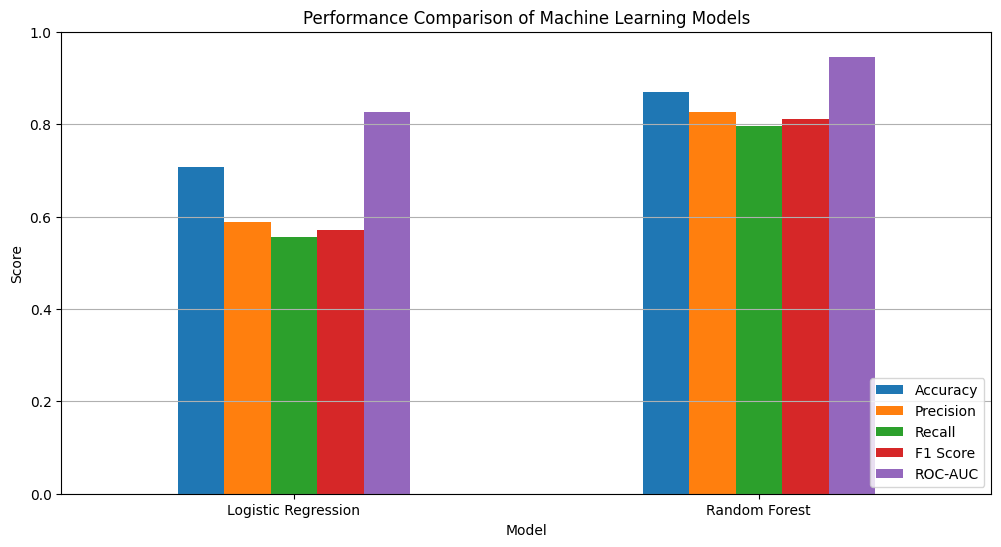

In [ ]:
# ============================================
# VISUAL MODEL COMPARISON
# ============================================

comparison_data = results.set_index('Model')

comparison_data.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Machine Learning Models')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(loc='lower right')

plt.grid(axis='y')

plt.show()

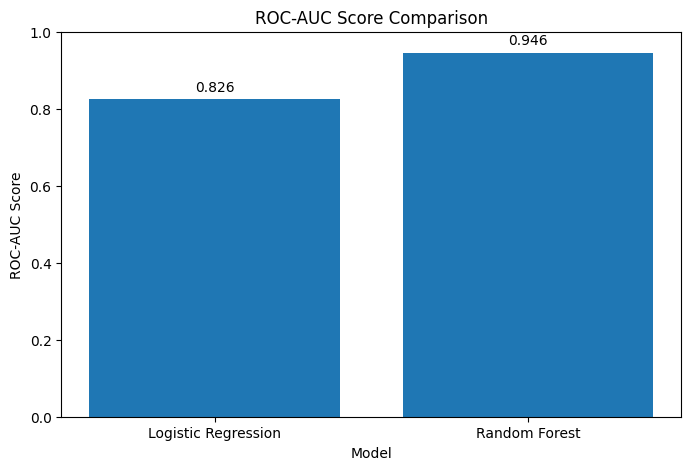

In [ ]:
# ============================================
# ROC-AUC COMPARISON
# ============================================

plt.figure(figsize=(8, 5))

models = ['Logistic Regression', 'Random Forest']
roc_scores = [lr_roc_auc, rf_roc_auc]

plt.bar(models, roc_scores)

plt.ylabel('ROC-AUC Score')
plt.xlabel('Model')
plt.title('ROC-AUC Score Comparison')

plt.ylim(0, 1)

for i, score in enumerate(roc_scores):
    plt.text(
        i,
        score + 0.02,
        f'{score:.3f}',
        ha='center'
    )

plt.show()

In [ ]:
# ============================================
# 7. BEST MODEL SELECTION
# ============================================

best_model_name = results.loc[
    results['ROC-AUC'].idxmax(),
    'Model'
]

best_roc_auc = results['ROC-AUC'].max()

print("Best Model:", best_model_name)
print(f"Best ROC-AUC Score: {best_roc_auc:.4f}")

Best Model: Random Forest
Best ROC-AUC Score: 0.9458


In [ ]:
# ============================================
# SELECT BEST MODEL OBJECT
# ============================================

if best_model_name == 'Logistic Regression':
    best_model = logistic_model
    best_scaler = scaler
else:
    best_model = rf_model
    best_scaler = None

print(f"Selected model: {best_model_name}")

Selected model: Random Forest


In [ ]:
# ============================================
# 8. SAVE BEST MODEL
# ============================================

joblib.dump(
    best_model,
    'diabetes_model.pkl'
)

print("Best model saved successfully!")

Best model saved successfully!


bold text

In [ ]:
# ============================================
# 9. CHECK SAVED FILES
# ============================================

import os

print("Saved files:")

for file in os.listdir('/content'):
    if file.endswith('.pkl'):
        print(file)

Saved files:
diabetes_model.pkl


In [ ]:
# ============================================
# 10. LOAD SAVED MODEL
# ============================================

loaded_model = joblib.load('diabetes_model.pkl')

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [ ]:
# ============================================
# RANDOM FOREST MODEL
# ============================================

from sklearn.ensemble import RandomForestClassifier
import joblib

# Create model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

# Save model
joblib.dump(rf_model, "random_forest_diabetes_model.pkl")

print("Random Forest model saved successfully!")

Random Forest trained successfully!
Random Forest model saved successfully!


In [ ]:
# ============================================
# LOAD RANDOM FOREST MODEL
# ============================================

rf_loaded_model = joblib.load(
    "random_forest_diabetes_model.pkl"
)

print("Random Forest model loaded successfully!")

Random Forest model loaded successfully!


In [ ]:
# ============================================
# PREDICT NEW PATIENT
# ============================================

new_patient = pd.DataFrame({
    'Pregnancies': [2],
    'Glucose': [120],
    'BloodPressure': [70],
    'SkinThickness': [30],
    'Insulin': [100],
    'BMI': [32.0],
    'DiabetesPedigreeFunction': [0.5],
    'Age': [35]
})

# Prediction
prediction = rf_loaded_model.predict(new_patient)[0]

# Probability
probability = rf_loaded_model.predict_proba(new_patient)[0][1]

print("Patient Information:")
display(new_patient)

print("\nPrediction Result")
print("=" * 40)

if prediction == 1:
    print("Result: Diabetes")
else:
    print("Result: No Diabetes")

print(f"Diabetes Probability: {probability:.2%}")

Patient Information:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,120,70,30,100,32.0,0.5,35



Prediction Result
Result: No Diabetes
Diabetes Probability: 13.00%
